# Retail Demand Forecasting & Inventory Planning

## Business objective
Forecast daily unit sales for each store-item combination over
January–March 2018 and demonstrate how forecasts can support
inventory replenishment planning.

## Dataset
- Historical daily sales: January 2013–December 2017.
- 10 stores and 50 items, giving 500 store-item combinations.
- 913,000 historical records.
- 45,000 future records requiring forecasts.
- Each historical row represents units sold for one item at one
  store on one day.

## Approach
1. Check data quality and inspect sales patterns.
2. Validate forecasts using January–March 2017, training only
   on earlier dates.
3. Compare a 52-week seasonal naïve baseline with Poisson regression.
4. Evaluate mean absolute error (MAE) and forecast bias.
5. Retrain on all historical data and forecast January–March 2018.
6. Illustrate reorder points using forecast lead-time demand
   and an assumed stock buffer.

## Scope and assumptions
- Recorded sales are used as a proxy for demand; stockout data
  is unavailable.
- Supplier lead time is assumed to be 7 days.
- The stock buffer is assumed to be 20% of lead-time demand;
  it is not a statistically calibrated safety-stock level.
- Current inventory positions are unavailable, so the project
  calculates reorder thresholds rather than actual order quantities.

In [1]:
from pathlib import Path

print(Path.cwd())

c:\Users\Admin\Desktop\Portfolio projects\retail-demand-forecasting\notebooks


## 1. Load and validate the data

Load the historical sales, future forecast dates, and sample
submission format. Convert date columns to datetime values.

Checks confirmed:
- No missing values in the historical data.
- No duplicate date-store-item records.
- No negative sales.
- All 500 store-item combinations contain 1,826 daily records.

A missing record is different from a recorded day with zero sales.

In [2]:
import pandas as pd

data_path = Path("../data")

train = pd.read_csv(data_path / "train.csv", parse_dates=["date"])
test = pd.read_csv(data_path / "test.csv", parse_dates=["date"])
sample_submission = pd.read_csv(data_path / "sample_submission.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

train.head()

Train: (913000, 4)
Test: (45000, 4)
Sample submission: (45000, 2)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [3]:
# Check column types and missing values
train.info()

# Each date-store-item combination should appear only once
print("\nDuplicate records:",
      train.duplicated(subset=["date", "store", "item"]).sum())

print("\nTraining dates:", train["date"].min(), "to", train["date"].max())
print("Forecast dates:", test["date"].min(), "to", test["date"].max())

print("\nStores:", train["store"].nunique())
print("Items:", train["item"].nunique())
print("Negative sales:", (train["sales"] < 0).sum())

# Check that every store-item pair has every historical day
expected_days = (train["date"].max() - train["date"].min()).days + 1
days_per_pair = train.groupby(["store", "item"])["date"].nunique()

print("\nStore-item pairs:", len(days_per_pair))
print("Expected days per pair:", expected_days)
print("Pairs with missing days:", (days_per_pair < expected_days).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[ns]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 27.9 MB

Duplicate records: 0

Training dates: 2013-01-01 00:00:00 to 2017-12-31 00:00:00
Forecast dates: 2018-01-01 00:00:00 to 2018-03-31 00:00:00

Stores: 10
Items: 50
Negative sales: 0

Store-item pairs: 500
Expected days per pair: 1826
Pairs with missing days: 0


## 2. Explore trend and seasonality

Aggregate sales across stores and items into daily totals, then
calculate average daily sales within each month.

Using averages avoids making longer months appear stronger simply
because they contain more days.

Observed patterns:
- Sales generally increase across the years.
- Sales are lower around January, rise towards midyear, and then decline.
- A repeating annual pattern suggests seasonality.

These aggregate patterns guide model design but may hide differences
between individual stores and items.

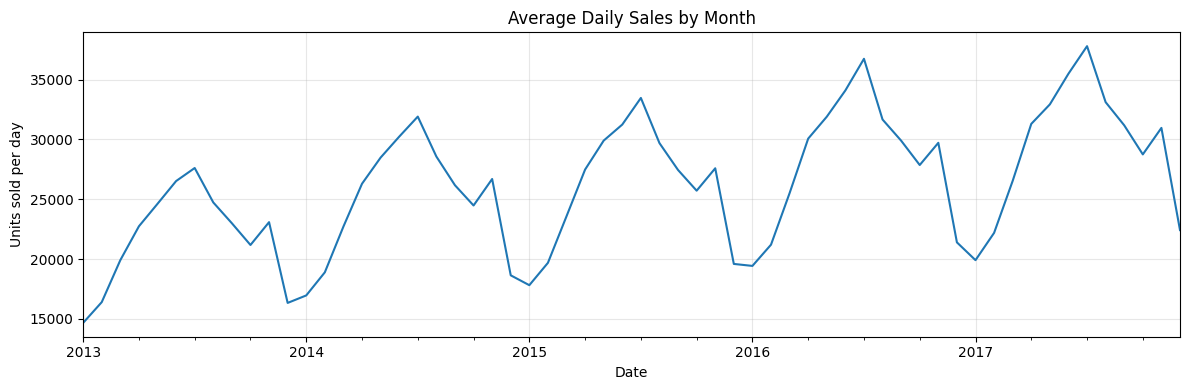

In [4]:
import matplotlib.pyplot as plt

# Total units sold across all stores and items each day
daily_sales = train.groupby("date")["sales"].sum().sort_index()

# Average daily total within each month
monthly_average = daily_sales.resample("MS").mean()

monthly_average.plot(figsize=(12, 4))

plt.title("Average Daily Sales by Month")
plt.xlabel("Date")
plt.ylabel("Units sold per day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Create a time-based validation period

Train using January 2013–December 2016 and evaluate on
January–March 2017.

The validation period matches the 90-day length and calendar months
of the final January–March 2018 forecast.

Training uses only dates before validation to reproduce forecasting
with information available at the time. April–December 2017 is set
aside at this stage, not deleted.

This single validation period provides a limited estimate of how
the methods may perform in other periods.

In [5]:
# Historical data available before our validation period
history = train[train["date"] < "2017-01-01"].copy()

# The next 90 days: actual sales kept for evaluation
validation = train[
    (train["date"] >= "2017-01-01") &
    (train["date"] < "2017-04-01")
].copy()

print("History:", history.shape)
print("Validation:", validation.shape)

print("\nHistory ends:", history["date"].max())
print("Validation starts:", validation["date"].min())
print("Validation ends:", validation["date"].max())

History: (730500, 4)
Validation: (45000, 4)

History ends: 2016-12-31 00:00:00
Validation starts: 2017-01-01 00:00:00
Validation ends: 2017-03-31 00:00:00


## 4. Establish a seasonal baseline

Predict each store-item day's sales using the same pair's sales
364 days (52 weeks) earlier.

This preserves the weekday and approximately matches the time of
year. It assumes the seasonal pattern repeats without adjusting
for growth.

Match records on reference date, store, and item to retrieve the
correct historical sales.

The baseline achieved a validation MAE of 7.52 units per
store-item-day. MAE measures the average absolute difference
between predicted and actual sales; lower is better.

In [6]:
# Historical sales to look up for each forecast
past_sales = history[["date", "store", "item", "sales"]].rename(
    columns={
        "date": "reference_date",
        "sales": "baseline_forecast"
    }
)

# Find the date 52 weeks before each validation date
baseline = validation.copy()
baseline["reference_date"] = baseline["date"] - pd.Timedelta(days=364)

# Match historical sales by reference date, store, and item
baseline = baseline.merge(
    past_sales,
    on=["reference_date", "store", "item"],
    how="left",
    validate="many_to_one"
)

print("Forecast rows:", len(baseline))
print("Missing forecasts:", baseline["baseline_forecast"].isna().sum())

baseline[
    ["date", "store", "item", "sales",
     "reference_date", "baseline_forecast"]
].head()

Forecast rows: 45000
Missing forecasts: 0


,date,store,item,sales,reference_date,baseline_forecast
0,2017-01-01,1,1,19,2016-01-03,12
1,2017-01-02,1,1,15,2016-01-04,12
2,2017-01-03,1,1,10,2016-01-05,12
3,2017-01-04,1,1,16,2016-01-06,16
4,2017-01-05,1,1,14,2016-01-07,12


In [7]:
# Error size for each store-item-day prediction
baseline["absolute_error"] = (
    baseline["sales"] - baseline["baseline_forecast"]
).abs()

# Average error across all 45,000 predictions
baseline_mae = baseline["absolute_error"].mean()

print(f"Baseline MAE: {baseline_mae:.2f} units")

baseline[
    ["date", "store", "item", "sales",
     "baseline_forecast", "absolute_error"]
].head()

Baseline MAE: 7.52 units


,date,store,item,sales,baseline_forecast,absolute_error
0,2017-01-01,1,1,19,12,7
1,2017-01-02,1,1,15,12,3
2,2017-01-03,1,1,10,12,2
3,2017-01-04,1,1,16,16,0
4,2017-01-05,1,1,14,12,2


In [8]:
print(f"Baseline MAE: {baseline_mae:.2f} units")

Baseline MAE: 7.52 units


## 5. Prepare model inputs

Create five inputs for each store-item-day:
- Store and item identifiers.
- Month to represent annual seasonality.
- Day of week to represent weekly patterns.
- Days since 1 January 2013 to represent the passage of time.

The same function prepares training, validation, and future inputs.
Actual sales are kept separately as the target variable.
All inputs are available before the forecast period begins.

In [9]:
# Create calendar inputs for the model
def make_features(data):
    features = data[["store", "item"]].copy()

    features["month"] = data["date"].dt.month
    features["day_of_week"] = data["date"].dt.dayofweek
    features["time_index"] = (
        data["date"] - pd.Timestamp("2013-01-01")
    ).dt.days

    return features

X_train = make_features(history)
y_train = history["sales"]

X_valid = make_features(validation)
y_valid = validation["sales"]

X_train.head()

,store,item,month,day_of_week,time_index
0,1,1,1,1,0
1,1,1,1,2,1
2,1,1,1,3,2
3,1,1,1,4,3
4,1,1,1,5,4


## 6. Train a calendar-based Poisson regression

One-hot encode store, item, month, and weekday so the model can
learn separate category effects. Standardize the time index to
support model fitting and regularization.

A pipeline fits preprocessing and regression using training data
only, then applies the fitted transformations to validation inputs.

Poisson regression produces positive expected sales forecasts.
The model uses fixed settings: alpha=0.1 and max_iter=300.
It assumes shared seasonal effects and a constant trend coefficient
on the log-sales scale.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error

# Prepare category columns and the time counter
preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"),
     ["store", "item", "month", "day_of_week"]),

    ("time", StandardScaler(), ["time_index"])
])

# Combine preparation and regression into one workflow
model = Pipeline([
    ("prepare", preprocessor),
    ("regression", PoissonRegressor(alpha=0.1, max_iter=300))
])

# Learn from historical inputs and sales
model.fit(X_train, y_train)

# Predict the validation period without using its actual sales
predictions = model.predict(X_valid)

# Compare predictions with actual validation sales
model_mae = mean_absolute_error(y_valid, predictions)

print(f"Baseline MAE: {baseline_mae:.2f} units")
print(f"Model MAE:    {model_mae:.2f} units")

Baseline MAE: 7.52 units
Model MAE:    5.83 units


## 7. Evaluate forecast performance

On the January–March 2017 validation period, Poisson regression
reduced MAE by 22.5% relative to the seasonal baseline.

This is a reduction in forecast error, not an accuracy percentage.

Mean error is calculated as forecast minus actual sales:
- Positive values indicate overprediction on average.
- Negative values indicate underprediction on average.

The model showed overall overprediction. The aggregate daily chart
followed the rises and falls in actual sales but was mostly above
them. Aggregate totals can hide offsetting errors between items
and stores.

The regression was selected because it had lower validation MAE.
Performance in other periods is not established by this single test.

In [11]:
improvement = (baseline_mae - model_mae) / baseline_mae * 100

print(f"Baseline MAE: {baseline_mae:.2f} units")
print(f"Model MAE: {model_mae:.2f} units")
print(f"Reduction in MAE: {improvement:.1f}%")

Baseline MAE: 7.52 units
Model MAE: 5.83 units
Reduction in MAE: 22.5%


In [12]:
# Positive means overprediction; negative means underprediction
errors = predictions - y_valid

print(f"Mean error: {errors.mean():.2f} units")

Mean error: 2.70 units


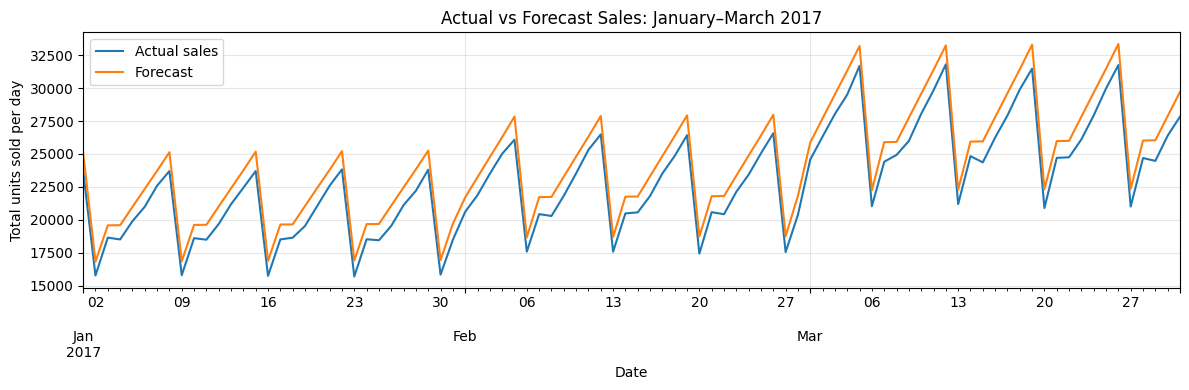

In [13]:
# Attach predictions to their corresponding validation rows
results = validation[["date", "store", "item", "sales"]].copy()
results["forecast"] = predictions

# Calculate daily totals across all stores and items
daily_comparison = results.groupby("date")[["sales", "forecast"]].sum()

daily_comparison.plot(figsize=(12, 4))

plt.title("Actual vs Forecast Sales: January–March 2017")
plt.xlabel("Date")
plt.ylabel("Total units sold per day")
plt.legend(["Actual sales", "Forecast"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Generate the final 90-day forecast

Create an untrained copy of the selected pipeline and refit it
using all historical sales from January 2013–December 2017.

Generate 45,000 daily forecasts for January–March 2018:
90 days × 500 store-item combinations.

All forecast rows were populated. Decimal predictions are retained
because they represent expected sales.

Actual sales for this period are unavailable in the supplied test
file, so final forecast accuracy cannot be measured locally.

In [14]:
from sklearn.base import clone

# Prepare all historical inputs and actual sales
X_full = make_features(train)
y_full = train["sales"]

# Prepare the future dates we want to predict
X_test = make_features(test)

# Create an untrained copy with the same model settings
final_model = clone(model)

# Learn from all five years of sales
final_model.fit(X_full, y_full)

# Forecast January–March 2018
future_predictions = final_model.predict(X_test)

# Attach forecasts to their dates, stores, and items
forecast = test[["id", "date", "store", "item"]].copy()
forecast["forecast_sales"] = future_predictions

print("Forecast rows:", len(forecast))
print("Missing forecasts:", forecast["forecast_sales"].isna().sum())

forecast.head()

Forecast rows: 45000
Missing forecasts: 0


,id,date,store,item,forecast_sales
0,0,2018-01-01,1,1,15.323242
1,1,2018-01-02,1,1,17.830558
2,2,2018-01-03,1,1,17.844709
3,3,2018-01-04,1,1,19.100589
4,4,2018-01-05,1,1,20.358275


## 9. Translate forecasts into inventory planning thresholds

Assume a seven-day supplier lead time. Sum forecasts for
1–7 January 2018 separately for each store-item pair.

Add an illustrative buffer equal to 20% of lead-time demand:

Reorder point = ceiling(lead-time demand + stock buffer)

Round the combined amount upward to whole units. Include the
planning dates, lead-time assumption, and buffer rate in the output.

The result contains 500 store-item planning thresholds.
These thresholds should be updated as the forecast window advances.

In [15]:
# Assumed supplier lead time
lead_time_days = 7

start_date = forecast["date"].min()
end_date = start_date + pd.Timedelta(days=lead_time_days)

# Select January 1–7; January 8 is excluded
lead_time_forecast = forecast[
    (forecast["date"] >= start_date) &
    (forecast["date"] < end_date)
]

# Expected demand during those seven days, for each pair
inventory_plan = (
    lead_time_forecast
    .groupby(["store", "item"])["forecast_sales"]
    .sum()
    .reset_index(name="lead_time_demand")
)

inventory_plan.head()

,store,item,lead_time_demand
0,1,1,134.953133
1,1,2,308.503774
2,1,3,202.496088
3,1,4,135.080913
4,1,5,118.951880


In [16]:
inventory_plan["period_start"] = start_date
inventory_plan["period_end"] = end_date - pd.Timedelta(days=1)

inventory_plan[
    ["store", "item", "period_start", "period_end", "lead_time_demand"]
].head()

,store,item,period_start,period_end,lead_time_demand
0,1,1,2018-01-01,2018-01-07,134.953133
1,1,2,2018-01-01,2018-01-07,308.503774
2,1,3,2018-01-01,2018-01-07,202.496088
3,1,4,2018-01-01,2018-01-07,135.080913
4,1,5,2018-01-01,2018-01-07,118.951880


In [17]:
import numpy as np

# Illustrative stock-buffer assumption
buffer_rate = 0.20

inventory_plan["stock_buffer"] = (
    inventory_plan["lead_time_demand"] * buffer_rate
)

# Round up because inventory is held in whole units
inventory_plan["reorder_point"] = np.ceil(
    inventory_plan["lead_time_demand"] +
    inventory_plan["stock_buffer"]
).astype(int)

inventory_plan[
    ["store", "item", "period_start", "period_end",
     "lead_time_demand", "stock_buffer", "reorder_point"]
].head()

,store,item,period_start,period_end,lead_time_demand,stock_buffer,reorder_point
0,1,1,2018-01-01,2018-01-07,134.953133,26.990627,162
1,1,2,2018-01-01,2018-01-07,308.503774,61.700755,371
2,1,3,2018-01-01,2018-01-07,202.496088,40.499218,243
3,1,4,2018-01-01,2018-01-07,135.080913,27.016183,163
4,1,5,2018-01-01,2018-01-07,118.951880,23.790376,143


In [18]:
inventory_plan["lead_time_days"] = lead_time_days
inventory_plan["buffer_rate"] = buffer_rate

inventory_plan = inventory_plan[
    ["store", "item", "period_start", "period_end",
     "lead_time_days", "buffer_rate", "lead_time_demand",
     "stock_buffer", "reorder_point"]
]

print("Store-item planning rows:", len(inventory_plan))
inventory_plan.head()

Store-item planning rows: 500


,store,item,period_start,period_end,lead_time_days,buffer_rate,lead_time_demand,stock_buffer,reorder_point
0,1,1,2018-01-01,2018-01-07,7,0.2,134.953133,26.990627,162
1,1,2,2018-01-01,2018-01-07,7,0.2,308.503774,61.700755,371
2,1,3,2018-01-01,2018-01-07,7,0.2,202.496088,40.499218,243
3,1,4,2018-01-01,2018-01-07,7,0.2,135.080913,27.016183,163
4,1,5,2018-01-01,2018-01-07,7,0.2,118.951880,23.790376,143


In [20]:
# Create an outputs folder beside data and notebooks
output_path = Path("../outputs")
output_path.mkdir(exist_ok=True)

# Save detailed daily forecasts
forecast.to_csv(
    output_path / "daily_sales_forecast.csv",
    index=False
)

# Save inventory planning thresholds and assumptions
inventory_plan.to_csv(
    output_path / "inventory_plan.csv",
    index=False
)

# Match the sample submission's ID order and column names
submission = sample_submission[["id"]].merge(
    forecast[["id", "forecast_sales"]],
    on="id",
    how="left",
    validate="one_to_one"
).rename(columns={"forecast_sales": "sales"})

assert submission["sales"].notna().all(), "Some forecasts are missing."

submission.to_csv(
    output_path / "submission.csv",
    index=False
)

print("Files saved to:", output_path.resolve())
print("Submission shape:", submission.shape)

Files saved to: C:\Users\Admin\Desktop\Portfolio projects\retail-demand-forecasting\outputs
Submission shape: (45000, 2)


## 10. Business interpretation and limitations

The model improved validation MAE by 22.5% over the seasonal baseline.
Forecasts can support replenishment planning by estimating demand
while waiting for supplier delivery.

Replenishment decisions require inventory position:
stock on hand + stock on order − backorders.

The reorder point indicates when replenishment should be triggered;
it does not specify the quantity to order.

Limitations:
- Validation covers one 90-day period.
- The model overpredicted on average during validation.
- Recorded sales may understate demand when stockouts occur.
- Prices, promotions, holidays, and stock availability are not included.
- Seven-day lead time and a 20% buffer are assumptions.
- The buffer does not establish a guaranteed service level.
- Inventory positions and ordering constraints are unavailable.

Before operational use, validate across additional periods and
replace inventory assumptions with business-specific information.

## Inventory Replenishment Analysis

The dataset contains historical sales demand but does not include actual inventory-on-hand information.

Therefore, current inventory positions cannot be directly observed. To demonstrate how the demand forecasts could support inventory replenishment decisions, a simulated current inventory snapshot will be created for each store-item combination.

The inventory analysis will combine:

- Current inventory position
- Forecast demand during the assumed 7-day supplier lead time
- Safety stock
- Reorder point
- Recommended reorder quantity

This allows the forecasting model to be translated into an operational inventory decision while clearly separating observed data from simulated business assumptions.

In [21]:
# Create one row for each store-item combination
inventory = (
    train.groupby(["store", "item"])
    .agg(
        current_inventory=("sales", "last")
    )
    .reset_index()
)

inventory.head()

,store,item,current_inventory
0,1,1,23
1,1,2,67
2,1,3,29
3,1,4,15
4,1,5,17


In [22]:
import numpy as np

# Set random seed so simulated inventory values stay reproducible
np.random.seed(42)

# Create one row for every store-item combination
inventory = (
    train[["store", "item"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Simulate current inventory levels
inventory["current_inventory"] = np.random.randint(
    100,
    401,
    size=len(inventory)
)

inventory.head()

,store,item,current_inventory
0,1,1,202
1,2,1,370
2,3,1,206
3,4,1,171
4,5,1,288


In [23]:
# Select the first 7 forecast days
first_7_days = test[
    test["date"] < test["date"].min() + pd.Timedelta(days=7)
].copy()

first_7_days.head()

,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [24]:
first_7_days["month"] = first_7_days["date"].dt.month
first_7_days["dayofweek"] = first_7_days["date"].dt.dayofweek

first_7_days["days_since_2013-01-01"] = (
    first_7_days["date"] - pd.Timestamp("2013-01-01")
).dt.days

In [25]:
features = [
    "store",
    "item",
    "month",
    "dayofweek",
    "days_since_2013-01-01"
]

In [26]:
first_7_days["forecast_sales"] = final_model.predict(
    first_7_days[features]
)

ValueError: columns are missing: {'day_of_week', 'time_index'}

In [27]:
final_model.feature_names_in_

array(['store', 'item', 'month', 'day_of_week', 'time_index'],
      dtype=object)

In [28]:
first_7_days.columns

Index(['id', 'date', 'store', 'item', 'month', 'dayofweek',
       'days_since_2013-01-01'],
      dtype='object')

In [29]:
first_7_days["day_of_week"] = first_7_days["date"].dt.dayofweek

first_7_days["time_index"] = (
    first_7_days["date"] - pd.Timestamp("2013-01-01")
).dt.days

In [30]:
features = [
    "store",
    "item",
    "month",
    "day_of_week",
    "time_index"
]

In [31]:
first_7_days["forecast_sales"] = final_model.predict(
    first_7_days[features]
)

In [32]:
first_7_days[
    ["date", "store", "item", "forecast_sales"]
].head(10)

,date,store,item,forecast_sales
0,2018-01-01,1,1,15.323242
1,2018-01-02,1,1,17.830558
2,2018-01-03,1,1,17.844709
3,2018-01-04,1,1,19.100589
4,2018-01-05,1,1,20.358275
5,2018-01-06,1,1,21.611569
6,2018-01-07,1,1,22.884191
90,2018-01-01,2,1,21.608637
91,2018-01-02,2,1,25.144421
92,2018-01-03,2,1,25.164377


In [33]:
forecast_7d = (
    first_7_days
    .groupby(["store", "item"])["forecast_sales"]
    .sum()
    .reset_index()
    .rename(columns={"forecast_sales": "forecast_7d"})
)

forecast_7d.head()

,store,item,forecast_7d
0,1,1,134.953133
1,1,2,308.503774
2,1,3,202.496088
3,1,4,135.080913
4,1,5,118.951880


In [34]:
forecast_7d = (
    first_7_days
    .groupby(["store", "item"])["forecast_sales"]
    .sum()
    .reset_index()
    .rename(columns={"forecast_sales": "forecast_7d"})
)

forecast_7d.head()

,store,item,forecast_7d
0,1,1,134.953133
1,1,2,308.503774
2,1,3,202.496088
3,1,4,135.080913
4,1,5,118.951880


### Combining Forecast Demand with Inventory Position

The 7-day demand forecast is combined with the simulated current inventory position for each store-item combination.

This creates the foundation for the replenishment analysis by bringing together:

- Current inventory available
- Expected demand during the 7-day supplier lead time
- Historical demand variability
- Safety stock requirements

The next step is to calculate the reorder point for each store-item combination.

In [35]:
inventory_plan = inventory.merge(
    forecast_7d,
    on=["store", "item"],
    how="left"
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d
0,1,1,202,134.953133
1,2,1,370,190.309156
2,3,1,206,169.258162
3,4,1,171,156.295353
4,5,1,288,114.060226


In [36]:
# Calculate historical daily demand variability
demand_variability = (
    train.groupby(["store", "item"])["sales"]
    .std()
    .reset_index()
    .rename(columns={"sales": "daily_sales_std"})
)

demand_variability.head()

,store,item,daily_sales_std
0,1,1,6.741022
1,1,2,15.005779
2,1,3,10.072529
3,1,4,6.640618
4,1,5,5.672102


In [37]:
inventory_plan = inventory_plan.merge(
    demand_variability,
    on=["store", "item"],
    how="left"
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std
0,1,1,202,134.953133,6.741022
1,2,1,370,190.309156,8.681013
2,3,1,206,169.258162,7.897391
3,4,1,171,156.295353,7.348810
4,5,1,288,114.060226,5.772961


### Safety Stock Calculation

Historical sales demand varies from day to day, so the inventory plan includes safety stock to reduce the risk of stockouts during the supplier lead time.

Safety stock is calculated using:

\[
\text{Safety Stock} = Z \times \sigma_d \times \sqrt{L}
\]

Where:

- \(Z\) is the z-score associated with the chosen service level
- \(\sigma_d\) is the standard deviation of daily sales
- \(L\) is the supplier lead time in days

A 95% service level is assumed, giving a z-score of 1.645. Supplier lead time is assumed to be 7 days.

This formulation assumes that supplier lead time is fixed and that demand variability is the main source of uncertainty.

In [38]:
service_level_z = 1.645
lead_time_days = 7

inventory_plan["safety_stock"] = (
    service_level_z
    * inventory_plan["daily_sales_std"]
    * np.sqrt(lead_time_days)
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std,safety_stock
0,1,1,202,134.953133,6.741022,29.338687
1,2,1,370,190.309156,8.681013,37.782032
2,3,1,206,169.258162,7.897391,34.371505
3,4,1,171,156.295353,7.348810,31.983937
4,5,1,288,114.060226,5.772961,25.125432


In [39]:
inventory_plan["reorder_point"] = (
    inventory_plan["forecast_7d"]
    + inventory_plan["safety_stock"]
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std,safety_stock,reorder_point
0,1,1,202,134.953133,6.741022,29.338687,164.291820
1,2,1,370,190.309156,8.681013,37.782032,228.091189
2,3,1,206,169.258162,7.897391,34.371505,203.629668
3,4,1,171,156.295353,7.348810,31.983937,188.279290
4,5,1,288,114.060226,5.772961,25.125432,139.185658


### Reorder Decision

A replenishment order is triggered when current inventory falls below the calculated reorder point.

The reorder point represents the stock level required to cover expected demand during the 7-day supplier lead time, plus safety stock for demand uncertainty.

In [40]:
inventory_plan["reorder"] = np.where(
    inventory_plan["current_inventory"] < inventory_plan["reorder_point"],
    "Yes",
    "No"
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std,safety_stock,reorder_point,reorder
0,1,1,202,134.953133,6.741022,29.338687,164.291820,No
1,2,1,370,190.309156,8.681013,37.782032,228.091189,No
2,3,1,206,169.258162,7.897391,34.371505,203.629668,No
3,4,1,171,156.295353,7.348810,31.983937,188.279290,Yes
4,5,1,288,114.060226,5.772961,25.125432,139.185658,No


In [41]:
inventory_plan["suggested_order_qty"] = np.where(
    inventory_plan["reorder"] == "Yes",
    inventory_plan["reorder_point"] - inventory_plan["current_inventory"],
    0
)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std,safety_stock,reorder_point,reorder,suggested_order_qty
0,1,1,202,134.953133,6.741022,29.338687,164.291820,No,0.00000
1,2,1,370,190.309156,8.681013,37.782032,228.091189,No,0.00000
2,3,1,206,169.258162,7.897391,34.371505,203.629668,No,0.00000
3,4,1,171,156.295353,7.348810,31.983937,188.279290,Yes,17.27929
4,5,1,288,114.060226,5.772961,25.125432,139.185658,No,0.00000


### Final Replenishment Quantities

Inventory decisions are converted into whole units because products are typically ordered as discrete quantities.

Reorder points, safety stock, and suggested order quantities are rounded upward using the ceiling function. Rounding upward avoids understating the amount of inventory required.

In [42]:
# Convert inventory planning quantities to whole units

inventory_plan["safety_stock"] = np.ceil(
    inventory_plan["safety_stock"]
).astype(int)

inventory_plan["reorder_point"] = np.ceil(
    inventory_plan["reorder_point"]
).astype(int)

inventory_plan["suggested_order_qty"] = np.ceil(
    inventory_plan["suggested_order_qty"]
).astype(int)

inventory_plan.head()

,store,item,current_inventory,forecast_7d,daily_sales_std,safety_stock,reorder_point,reorder,suggested_order_qty
0,1,1,202,134.953133,6.741022,30,165,No,0
1,2,1,370,190.309156,8.681013,38,229,No,0
2,3,1,206,169.258162,7.897391,35,204,No,0
3,4,1,171,156.295353,7.348810,32,189,Yes,18
4,5,1,288,114.060226,5.772961,26,140,No,0


In [43]:
replenishment_plan = inventory_plan[
    [
        "store",
        "item",
        "current_inventory",
        "forecast_7d",
        "safety_stock",
        "reorder_point",
        "reorder",
        "suggested_order_qty"
    ]
].copy()

replenishment_plan["forecast_7d"] = (
    replenishment_plan["forecast_7d"]
    .round(1)
)

replenishment_plan.head(10)

,store,item,current_inventory,forecast_7d,safety_stock,reorder_point,reorder,suggested_order_qty
0,1,1,202,135.0,30,165,No,0
1,2,1,370,190.3,38,229,No,0
2,3,1,206,169.3,35,204,No,0
3,4,1,171,156.3,32,189,Yes,18
4,5,1,288,114.1,26,140,No,0
5,6,1,120,114.0,25,139,Yes,19
6,7,1,202,104.6,24,128,No,0
7,8,1,221,182.2,38,220,No,0
8,9,1,314,156.7,34,191,No,0
9,10,1,187,167.0,35,202,Yes,15


### Replenishment Summary

The replenishment plan identifies which store-item combinations require additional stock based on current inventory, forecast demand during the 7-day lead time, and safety stock requirements.

The next step is to summarize the number of reorder actions and identify the largest replenishment requirements.

In [44]:
reorder_summary = replenishment_plan["reorder"].value_counts()

reorder_summary

reorder
Yes    356
No     144
Name: count, dtype: int64

In [45]:
reorder_required = replenishment_plan[
    replenishment_plan["reorder"] == "Yes"
].copy()

reorder_required.sort_values(
    "suggested_order_qty",
    ascending=False
).head(10)

,store,item,current_inventory,forecast_7d,safety_stock,reorder_point,reorder,suggested_order_qty
277,8,28,105,614.0,124,738,Yes,633
271,2,28,148,641.4,129,770,Yes,622
272,3,28,116,570.4,115,685,Yes,569
71,2,8,140,563.8,115,679,Yes,539
122,3,13,128,547.9,112,660,Yes,532
91,2,10,132,537.6,109,647,Yes,515
171,2,18,229,615.8,125,741,Yes,512
449,10,45,135,517.2,106,624,Yes,489
219,10,22,136,516.7,105,622,Yes,486
177,8,18,229,589.5,120,710,Yes,481


### Replenishment Analysis Results

The simulated inventory scenario contains 500 store-item combinations.

Of these:

- 356 combinations require replenishment
- 144 combinations remain above their reorder point
- Approximately 71.2% of store-item combinations trigger a reorder under the simulated inventory assumptions

The largest replenishment requirements occur where forecast lead-time demand is high relative to current inventory.

For example, Store 8, Item 28 has:

- Current inventory: 105 units
- 7-day forecast demand: approximately 614 units
- Safety stock: 124 units
- Reorder point: 738 units
- Suggested replenishment quantity: 633 units

These results demonstrate how demand forecasts can be translated into actionable inventory decisions.

Because actual inventory-on-hand data was not available in the source dataset, current inventory values were simulated. Therefore, the replenishment quantities should be interpreted as a demonstration of the decision framework rather than real operational recommendations.

In [46]:
summary_metrics = {
    "total_store_item_combinations": len(replenishment_plan),
    "reorders_required": (replenishment_plan["reorder"] == "Yes").sum(),
    "reorder_rate_pct": (
        (replenishment_plan["reorder"] == "Yes").mean() * 100
    ),
    "total_units_to_order": replenishment_plan["suggested_order_qty"].sum(),
    "average_order_qty": (
        reorder_required["suggested_order_qty"].mean()
    ),
    "largest_order_qty": replenishment_plan["suggested_order_qty"].max()
}

summary_metrics

{'total_store_item_combinations': 500,
 'reorders_required': np.int64(356),
 'reorder_rate_pct': np.float64(71.2),
 'total_units_to_order': np.int64(70748),
 'average_order_qty': np.float64(198.73033707865167),
 'largest_order_qty': np.int64(633)}

### Inventory Planning Summary

The replenishment analysis evaluated 500 store-item combinations using forecast demand, simulated current inventory, historical demand variability, and a 7-day supplier lead time.

Key results from the simulated inventory scenario were:

- 500 store-item combinations analyzed
- 356 combinations required replenishment
- 71.2% of combinations fell below their reorder point
- 70,748 total units were suggested for replenishment
- Average replenishment quantity among items requiring an order was approximately 198.7 units
- The largest individual replenishment requirement was 633 units

These figures demonstrate how the demand forecasting model can be translated into operational inventory decisions.

Because actual inventory-on-hand data was not included in the source dataset, current inventory levels were simulated. Therefore, these replenishment results illustrate the decision-making framework rather than actual business inventory requirements.

## Checkpoint: Forecasting and Inventory Planning

### Objective

The goal of this stage was to move beyond demand forecasting and demonstrate how predicted sales can support inventory replenishment decisions.

The forecasting model was first evaluated using a validation period and then retrained using the full historical training dataset to make final future demand predictions.

### Forecasting Workflow

The final forecasting workflow included:

1. Creating time-based features such as month, day of week, and time index
2. Training and validating the forecasting model
3. Evaluating predicted versus actual sales
4. Retraining the model using the complete training dataset
5. Generating forecasts for the future test period
6. Aggregating the first 7 forecast days to estimate demand during the assumed supplier lead time

### Inventory Planning Assumptions

The source dataset contains historical sales but does not include actual inventory-on-hand data.

To demonstrate inventory planning, current inventory levels were therefore simulated for each store-item combination.

The following assumptions were used:

- Supplier lead time: 7 days
- Service level: 95%
- Z-score: 1.645
- Current inventory: simulated
- Demand uncertainty estimated from historical daily sales variability

### Safety Stock

Safety stock was calculated using:

\[
Safety\ Stock = Z \times \sigma_d \times \sqrt{L}
\]

Where:

- \(Z\) = service-level z-score
- \(\sigma_d\) = standard deviation of historical daily sales
- \(L\) = supplier lead time in days

This approach assumes that supplier lead time is fixed and that demand variability is the primary source of uncertainty.

### Reorder Point

The reorder point was calculated as:

\[
Reorder\ Point = Forecast\ Lead-Time\ Demand + Safety\ Stock
\]

A reorder was triggered when:

\[
Current\ Inventory < Reorder\ Point
\]

The suggested order quantity was then calculated as the difference between the reorder point and current inventory.

### Results

The simulated replenishment scenario produced the following results:

- 500 store-item combinations analyzed
- 356 combinations required replenishment
- 71.2% reorder rate
- 70,748 total units suggested for replenishment
- Average suggested order quantity: approximately 198.7 units
- Largest individual suggested order: 633 units

### Business Interpretation

The analysis demonstrates how a sales forecasting model can support practical inventory decisions.

Instead of using forecasts only as predictive outputs, the model was connected to:

- expected lead-time demand
- safety stock
- reorder thresholds
- replenishment quantities

This transforms the forecasting model into a decision-support framework for inventory planning.

### Limitation

The replenishment results should not be interpreted as real operational recommendations because actual inventory balances were not available in the dataset.

The simulated inventory levels were used only to demonstrate how forecasting outputs could be incorporated into an inventory management process.

### Key Learning

This stage demonstrated the difference between predictive analytics and decision analytics.

The forecasting model answers:

> How much demand is expected?

The inventory planning layer answers:

> Given expected demand and available inventory, what action should the business take?

Combining both creates a more useful business analytics solution.

## Management-Facing Replenishment Output

The final replenishment table is designed to highlight the store-item combinations that require action.

Only combinations requiring replenishment are included, and the table is ranked by suggested order quantity so that the largest inventory shortfalls appear first.

In [47]:
management_replenishment = (
    replenishment_plan[
        replenishment_plan["reorder"] == "Yes"
    ]
    .sort_values(
        "suggested_order_qty",
        ascending=False
    )
    .reset_index(drop=True)
)

management_replenishment.head(15)

,store,item,current_inventory,forecast_7d,safety_stock,reorder_point,reorder,suggested_order_qty
0,8,28,105,614.0,124,738,Yes,633
1,2,28,148,641.4,129,770,Yes,622
2,3,28,116,570.4,115,685,Yes,569
3,2,8,140,563.8,115,679,Yes,539
4,3,13,128,547.9,112,660,Yes,532
5,2,10,132,537.6,109,647,Yes,515
6,2,18,229,615.8,125,741,Yes,512
7,10,45,135,517.2,106,624,Yes,489
8,10,22,136,516.7,105,622,Yes,486
9,8,18,229,589.5,120,710,Yes,481


### Priority Replenishment View

The table below prioritizes inventory actions based on the largest suggested replenishment quantities.

This can help inventory managers quickly identify:

- the stores with the largest stock shortfalls
- the items with the highest expected lead-time demand
- the replenishment quantities requiring the most immediate attention

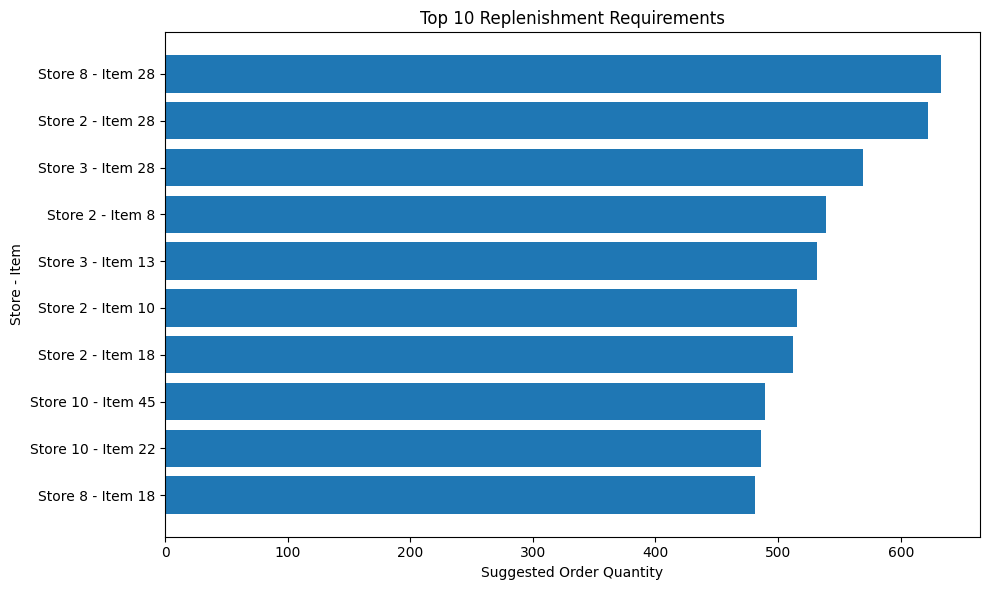

In [50]:
top_10_reorders = management_replenishment.head(10).copy()

top_10_reorders["store_item"] = (
    "Store "
    + top_10_reorders["store"].astype(str)
    + " - Item "
    + top_10_reorders["item"].astype(str)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_reorders["store_item"],
    top_10_reorders["suggested_order_qty"]
)

plt.xlabel("Suggested Order Quantity")
plt.ylabel("Store - Item")
plt.title("Top 10 Replenishment Requirements")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "../images/top_replenishment_requirements.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The chart highlights the store-item combinations with the largest simulated replenishment requirements.

Store 8 - Item 28 has the highest suggested order quantity, followed closely by Store 2 - Item 28.

Item 28 appears multiple times among the largest replenishment requirements, indicating that forecast demand for this item is relatively high across several stores.

This visualization helps prioritize replenishment actions by showing where the largest inventory shortfalls occur.

Because current inventory levels were simulated, the chart should be interpreted as a demonstration of the replenishment framework rather than actual operational stock requirements.

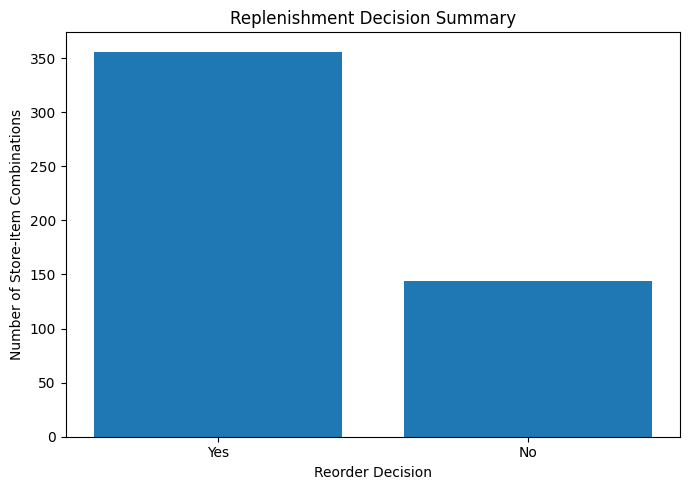

In [51]:
reorder_counts = replenishment_plan["reorder"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    reorder_counts.index,
    reorder_counts.values
)

plt.xlabel("Reorder Decision")
plt.ylabel("Number of Store-Item Combinations")
plt.title("Replenishment Decision Summary")

plt.tight_layout()

plt.savefig(
    "../images/replenishment_decision_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Replenishment Decision Summary

The simulated scenario indicates that 356 of 500 store-item combinations require replenishment, while 144 remain above their calculated reorder point.

This corresponds to a reorder rate of approximately 71.2%.

The relatively high reorder rate reflects the simulated inventory assumptions and should not be interpreted as evidence of actual stock shortages in the original dataset.

## Project Conclusion

### Business Problem

The objective of this project was to forecast future retail demand and demonstrate how those forecasts could support inventory replenishment decisions.

The dataset contained historical daily sales across multiple stores and items. The challenge was not only to predict future sales, but also to translate those predictions into a practical inventory planning framework.

### Approach

The project followed these main stages:

1. Explored historical sales patterns
2. Created time-based forecasting features
3. Trained and evaluated a forecasting model using a holdout validation period
4. Retrained the final model using the full historical training dataset
5. Generated future sales forecasts
6. Aggregated the first 7 forecast days to represent supplier lead-time demand
7. Estimated historical demand variability
8. Calculated safety stock using a 95% service level
9. Calculated reorder points
10. Compared reorder points with simulated current inventory
11. Generated reorder decisions and suggested replenishment quantities

### Key Results

The inventory simulation evaluated 500 store-item combinations.

Results included:

- 356 combinations requiring replenishment
- 144 combinations remaining above their reorder point
- 71.2% simulated reorder rate
- 70,748 total suggested replenishment units
- Average suggested replenishment quantity of approximately 198.7 units
- Largest individual suggested order of 633 units

The largest replenishment requirement occurred for Store 8 - Item 28.

### Business Value

The project demonstrates how forecasting can be extended beyond prediction into operational decision support.

The forecasting model estimates expected demand, while the inventory planning layer converts those forecasts into:

- safety stock requirements
- reorder points
- replenishment triggers
- suggested order quantities

This provides a practical example of how predictive analytics can support inventory management decisions.

### Limitations

The dataset does not include actual inventory balances, supplier lead-time records, holding costs, stockout costs, or order constraints.

Current inventory levels were therefore simulated.

The inventory results should consequently be interpreted as a demonstration of the replenishment methodology rather than actual operational recommendations.

The safety-stock calculation also assumes a fixed 7-day supplier lead time and treats demand variability as the primary source of uncertainty.

### Potential Improvements

Future extensions could include:

- actual inventory-on-hand data
- variable supplier lead times
- minimum order quantities
- supplier capacity constraints
- holding and stockout costs
- product-level service targets
- automated replenishment dashboards
- more advanced forecasting models

## Key Learning

This project reinforced several important analytics concepts:

- Forecast accuracy should be evaluated before using a model for future predictions.
- Validation data should remain separate during model evaluation.
- Once model evaluation is complete, retraining on the full historical dataset allows the final model to use all available information.
- Forecasts become more valuable when translated into business decisions.
- Safety stock provides protection against demand uncertainty.
- Reorder points combine expected lead-time demand with safety stock.
- Business assumptions and simulated variables must be clearly documented.
- A technically correct model is only one part of an effective analytics solution.